## short-term trading

In [1]:
import os
import datetime as dt

from dotenv import load_dotenv
from pathlib import Path

import json
import time
from urllib.parse import urljoin, urlencode
import requests

import numpy as np
import pandas as pd

import plotly
import plotly.graph_objs as go
import plotly.express as px
import seaborn as sns
import matplotlib.pyplot as plt

from Modules.utility import Utility
from Modules.show_plot import ShowPlot
from Modules.reques_api import RequestApi
from Modules.get_market_data import GetMarketData
from Modules.stock_prices_and_market_data import ClassStockPricesMarketData
from Modules.financial import Financial
from Modules.pdf_url_to_markdown import PDFUrlToMarkdown
from Modules.webpage_to_markdown import WebpageToMarkdown
from Modules.compute_fibonacci_extension import ComputeFibonacciExtension

In [2]:
# FRED API key for accessing Federal Reserve Economic Data
FRED_API_KEY = os.getenv("FRED_API_KEY")
# Output directory for storing downloaded data
API_BASE_URL = os.getenv("API_BASE_URL", "http://localhost:8000")
request_api = RequestApi(API_BASE_URL)
get_market_data = GetMarketData(Path('/workspace/data'))
utility = Utility()
stock_prices_market_data = ClassStockPricesMarketData()
financial = Financial()
# URLからPDFをダウンロードしてMarkdownに変換するクラスのインスタンスを作成
pdf_to_md = PDFUrlToMarkdown()
# WEBページをMarkdownに変換する関数
webpage_to_markdown = WebpageToMarkdown()
# Fibonacciエクステンションを計算するクラスのインスタンスを作成
fibonacci_extension = ComputeFibonacciExtension()

In [3]:
# Date range for fetching API s
start = '2007-01-01'
end = dt.datetime.now().strftime('%Y-%m-%d')
output_dir = Path("/workspace/data/")
output_dir.mkdir(parents=True, exist_ok=True)
# Define sector ETFs, benchmarks, and commodities for analysis
sector_etfs = {
    "oil": "XOP",
    "uranium": "URNM",
    "gold": "GDX",
    "silver": "SIL",
    "copper": "COPX",
    "critical_minerals": "REMX",
}
# Define benchmarks for analysis
benchmarks = {
    "SP500": "SPY",
    "NASDAQ100": "QQQ",
    "RUSSELL2000": "IWM"
}
# Define commodities for analysis
commodities = {
    "WTI": "CL=F",
    "BRENT": "BZ=F",
    "NATGAS": "NG=F",
    "GOLD": "GC=F",
    "SILVER": "SI=F",
    "COPPER": "HG=F",
    "URANIUM": "SRUUF"
}

#### Functions

In [4]:
def get_stock_timeseries_data(
    start_date: str,
    end_date: str,
    code: str,
    market: str | None,
) -> pd.DataFrame:
    # Fetch market data from the API based on the provided parameters
    response = request_api.update_stock_timeseries_data(
        code=code,
        market=market,
        start=start_date,
        end=end_date
    )
    # Retrieve the time series data from the API
    if response is None:
        return pd.DataFrame()
    # If the response is valid, proceed to fetch the time series data
    df = request_api.get_stock_time_series_data(
        code=code,
        market=market,
        start=start_date,
        end=end_date
    )
    df["date"] = pd.to_datetime(df["date"])
    return df

In [5]:
def get_commodity_timeseries_data(
    start_date: str,
    end_date: str,
    code: str,
    market: str | None,
) -> pd.DataFrame:
    # Fetch market data from the API based on the provided parameters
    response = request_api.update_commodity_timeseries_data(
        code=code,
        market=market,
        start=start_date,
        end=end_date
    )
    # Retrieve the time series data from the API
    if response is None:
        return pd.DataFrame()
    # If the response is valid, proceed to fetch the time series data
    df = request_api.get_commodity_time_series_data(
        code=code,
        market=market,
        start=start_date,
        end=end_date
    )
    df["date"] = pd.to_datetime(df["date"])
    return df

#### 各サブセクタのデータフレーム取得

In [6]:
sector_dfs: dict[str, pd.DataFrame] = {
    name: get_stock_timeseries_data(
        start_date=start,
        end_date=end,
        code=code,
        market=None,
    )
    for name, code in sector_etfs.items()
}

# 個別に使いたい場合のセクターETFデータフレームの取得
oil_sector_etf_df = sector_dfs["oil"]  # 個別に使いたい場合
uranium_sector_etf_df = sector_dfs["uranium"]  # 個別に使いたい場合
gold_sector_etf_df = sector_dfs["gold"]  # 個別に使いたい場合
silver_sector_etf_df = sector_dfs["silver"]  # 個別に使いたい場合
copper_sector_etf_df = sector_dfs["copper"]  # 個別に使いたい場合
critical_minerals_sector_etf_df = sector_dfs["critical_minerals"]  # 個別に使いたい場合

取得件数: 5004
取得件数: 1722
取得件数: 5004
取得件数: 4146
取得件数: 4146
取得件数: 4012


#### インデクスのデータフレーム取得

In [7]:

benchmark_dfs: dict[str, pd.DataFrame] = {
    name: get_stock_timeseries_data(
        start_date=start,
        end_date=end,
        code=code,
        market=None,
    )
    for name, code in benchmarks.items()
}

# 個別に使いたい場合
sp500_df = benchmark_dfs["SP500"]  # 例: S&P 500
nasdaq_df = benchmark_dfs["NASDAQ100"]  # 例: NASDAQ
russell2000_df = benchmark_dfs["RUSSELL2000"]  # 例: Russell 2000

取得件数: 5004
取得件数: 5004
取得件数: 5004


#### 原資産の時系列をデータフレーム化

In [8]:
commodity_dfs: dict[str, pd.DataFrame] = {
    name: get_commodity_timeseries_data(
        start_date=start,
        end_date=end,
        code=code,
        market=None,
    )
    for name, code in commodities.items()
}

# 個別に使いたい場合のコモディティデータフレームの取得
wti_df = commodity_dfs["WTI"]  # 個別に使いたい場合
brent_df = commodity_dfs["BRENT"]  # 個別に使いたい場合
natural_gas_df = commodity_dfs["NATGAS"]  # 個別に使いたい場合
gold_df = commodity_dfs["GOLD"]  # 個別に使いたい場合
silver_df = commodity_dfs["SILVER"]  # 個別に使いたい場合
copper_df = commodity_dfs["COPPER"]  # 個別に使いたい場合
uranium_df = commodity_dfs["URANIUM"]  # 個別に使いたい場合

取得件数: 5184
取得件数: 4780
取得件数: 5005
取得件数: 5183
取得件数: 5003
取得件数: 5006
取得件数: 1312


#### No.1 データ統合

In [9]:
sector_close = pd.DataFrame({
    name: df.set_index("date")["close"]
    for name, df in sector_dfs.items()
})

benchmark_close = pd.DataFrame({
    name: df.set_index("date")["close"]
    for name, df in benchmark_dfs.items()
})

commodity_close = pd.DataFrame({
    name: df.set_index("date")["close"]
    for name, df in commodity_dfs.items()
})

sector_close = sector_close.sort_index()
benchmark_close = benchmark_close.sort_index()
commodity_close = commodity_close.sort_index()

# 日付ソート
sector_close = sector_close.sort_index()
benchmark_close = benchmark_close.sort_index()
commodity_close = commodity_close.sort_index()

# 前方補完
sector_close = sector_close.ffill()
benchmark_close = benchmark_close.ffill()
commodity_close = commodity_close.ffill()

# 全列で欠損のある行を除去
sector_close = sector_close.dropna()
benchmark_close = benchmark_close.dropna()
commodity_close = commodity_close.dropna()

all_data = pd.concat(
    [
        sector_close.add_prefix("sector_"),
        benchmark_close.add_prefix("benchmark_"),
        commodity_close.add_prefix("commodity_")
    ],
    axis=1
)

all_data = all_data.ffill()

print(all_data.shape)
all_data.tail()

(5008, 16)


/tmp/ipykernel_728/2612706987.py:35: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  all_data = pd.concat(


,sector_oil,sector_uranium,sector_gold,sector_silver,sector_copper,sector_critical_minerals,benchmark_SP500,benchmark_NASDAQ100,benchmark_RUSSELL2000,commodity_WTI,commodity_BRENT,commodity_NATGAS,commodity_GOLD,commodity_SILVER,commodity_COPPER,commodity_URANIUM
date,,,,,,,,,,,,,,,,
2026-10-06,185.979996,48.549999,87.720001,86.629997,86.440002,63.529999,778.150024,760.520020,284.399994,89.269997,100.260002,3.078,4169.200195,60.919998,6.5775,19.430000
2026-10-07,189.520004,49.090000,85.320000,83.500000,84.139999,62.820000,775.770020,753.789978,278.250000,89.959999,100.970001,3.114,4195.000000,60.880001,6.5800,19.680000
2026-10-08,191.589996,47.330002,85.410004,83.199997,82.709999,60.799999,774.859985,753.969971,276.320007,89.000000,101.129997,3.288,4139.899902,59.063999,6.5300,19.360001
2026-10-09,192.619995,46.400002,88.639999,86.370003,85.050003,61.200001,776.239990,752.549988,278.209991,91.290001,103.900002,3.129,4159.700195,60.669998,6.5345,18.719999
2026-10-12,194.100006,46.125999,88.230003,85.809998,85.290001,58.799999,778.780029,749.690002,278.470001,91.830002,104.639999,3.170,4220.799805,60.140999,6.6895,19.030001


In [10]:
print(sector_close.shape)
print(benchmark_close.shape)

(1722, 6)
(5004, 3)


#### No.2 リターン作成

In [11]:
returns = sector_close.pct_change()

returns_20d = sector_close.pct_change(20)
returns_60d = sector_close.pct_change(60)

returns.columns = [f"{c}_ret" for c in returns.columns]
returns_20d.columns = [f"{c}_20d" for c in returns_20d.columns]
returns_60d.columns = [f"{c}_60d" for c in returns_60d.columns]

returns.tail()

,oil_ret,uranium_ret,gold_ret,silver_ret,copper_ret,critical_minerals_ret
date,,,,,,
2026-10-06,0.007039,0.022751,-0.001366,-0.004253,0.005116,0.004427
2026-10-07,0.019034,0.011123,-0.027360,-0.036131,-0.026608,-0.011176
2026-10-08,0.010922,-0.035852,0.001055,-0.003593,-0.016995,-0.032155
2026-10-09,0.005376,-0.019649,0.037818,0.038101,0.028292,0.006579
2026-10-12,0.007684,-0.005905,-0.004625,-0.006484,0.002822,-0.039216


#### No.3 ベンチマーク比較

In [12]:
benchmark_ret = benchmark_close["SP500"].pct_change(20)

relative_perf = pd.DataFrame(index=sector_close.index)

for sector in sector_close.columns:

    sector_ret = sector_close[sector].pct_change(20)

    relative_perf[sector] = (
        sector_ret - benchmark_ret
    )

relative_perf.tail()

,oil,uranium,gold,silver,copper,critical_minerals
date,,,,,,
2026-10-06,-0.051042,-0.166284,-0.127273,-0.138472,-0.093373,-0.182557
2026-10-07,-0.046878,-0.156744,-0.168527,-0.189776,-0.138339,-0.199319
2026-10-08,-0.054236,-0.169791,-0.139938,-0.165237,-0.102256,-0.199551
2026-10-09,-0.020380,-0.164173,-0.115029,-0.139037,-0.069107,-0.168764
2026-10-12,-0.048653,-0.127358,-0.089292,-0.106812,-0.024724,-0.179756


#### No.4 Relative Strength作成

In [13]:
relative_strength = pd.DataFrame(index=sector_close.index)

for sector in sector_close.columns:

    rs = (
        sector_close[sector]
        .div(benchmark_close["SP500"], fill_value=np.nan)
    )

    relative_strength[sector] = rs

relative_strength = relative_strength.dropna()

relative_strength = (
    relative_strength /
    relative_strength.iloc[0]
) * 100

relative_strength.tail()

,oil,uranium,gold,silver,copper,critical_minerals
date,,,,,,
2026-10-06,97.451641,167.865786,124.402741,112.568678,200.945702,70.777246
2026-10-07,99.611235,170.253614,121.370324,108.834374,196.199004,70.200965
2026-10-08,100.817484,164.342384,121.641051,108.570709,193.091016,68.023424
2026-10-09,101.179287,160.826747,126.016783,112.506994,198.200893,68.349220
2026-10-12,101.624168,159.355582,125.024794,111.412952,198.111916,65.454673


#### No.5 20日ランキング

In [14]:
latest_20d_rank = (
    returns_20d.iloc[-1]
    .sort_values(ascending=False)
    .to_frame("return_20d")
)

latest_20d_rank["rank"] = range(
    1,
    len(latest_20d_rank) + 1
)

latest_20d_rank

,return_20d,rank
copper_20d,0.003884,1
oil_20d,-0.020045,2
gold_20d,-0.060683,3
silver_20d,-0.078204,4
uranium_20d,-0.098750,5
critical_minerals_20d,-0.151148,6


#### No.6 60日ランキング

In [15]:
latest_60d_rank = (
    returns_60d.iloc[-1]
    .sort_values(ascending=False)
    .to_frame("return_60d")
)

latest_60d_rank["rank"] = range(
    1,
    len(latest_60d_rank) + 1
)

latest_60d_rank

,return_60d,rank
gold_60d,0.253267,1
silver_60d,0.214235,2
copper_60d,0.181138,3
oil_60d,0.153920,4
uranium_60d,-0.031983,5
critical_minerals_60d,-0.171831,6


#### No.7 セクターローテーションスコア

In [ ]:
# ============================================================
# No.7 セクターローテーションスコア
# ============================================================

rotation_score = pd.DataFrame(
    index=sector_close.columns
)

# 20日リターン
rotation_score["score20"] = (
    returns_20d.iloc[-1]
    .rename(lambda x: x.replace("_20d", ""))
)

# 60日リターン
rotation_score["score60"] = (
    returns_60d.iloc[-1]
    .rename(lambda x: x.replace("_60d", ""))
)

# 念のため欠損除去
rotation_score = rotation_score.dropna()

# Zスコア化
rotation_score["z20"] = (
    rotation_score["score20"]
    - rotation_score["score20"].mean()
) / rotation_score["score20"].std()

rotation_score["z60"] = (
    rotation_score["score60"]
    - rotation_score["score60"].mean()
) / rotation_score["score60"].std()

# 総合スコア
rotation_score["rotation_score"] = (
    0.7 * rotation_score["z20"]
    + 0.3 * rotation_score["z60"]
)

# 降順ランキング
rotation_score = rotation_score.sort_values(
    "rotation_score",
    ascending=False
)

rotation_score

,score20,score60,z20,z60,rotation_score
copper,0.003884,0.181138,1.282669,0.490824,0.886747
oil,-0.020045,0.153920,0.852649,0.326594,0.589622
gold,-0.060683,0.253267,0.122334,0.926026,0.524180
silver,-0.078204,0.214235,-0.192523,0.690520,0.248998
uranium,-0.098750,-0.031983,-0.561745,-0.795084,-0.678414
critical_minerals,-0.151148,-0.171831,-1.503384,-1.638880,-1.571132


In [17]:
print("returns_20d index")
print(returns_20d.iloc[-1].index.tolist())

print()

print("rotation_score index")
print(rotation_score.index.tolist())

print()

print(rotation_score[["score20", "score60"]])

returns_20d index
['oil_20d', 'uranium_20d', 'gold_20d', 'silver_20d', 'copper_20d', 'critical_minerals_20d']

rotation_score index
['copper', 'oil', 'gold', 'silver', 'uranium', 'critical_minerals']

                    score20   score60
copper             0.003884  0.181138
oil               -0.020045  0.153920
gold              -0.060683  0.253267
silver            -0.078204  0.214235
uranium           -0.098750 -0.031983
critical_minerals -0.151148 -0.171831


#### No.8 可視化

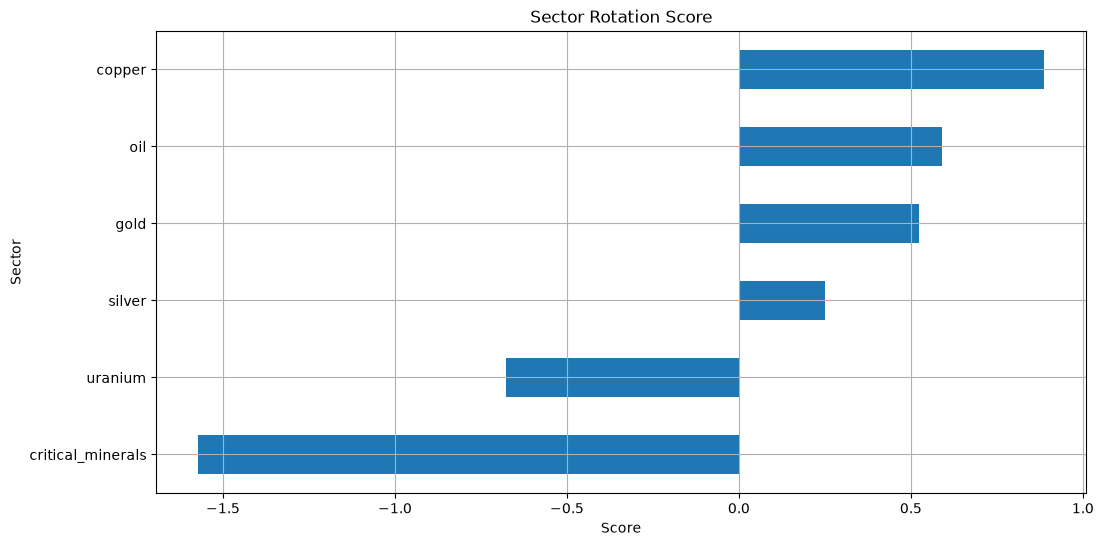

In [18]:
plt.figure(figsize=(12, 6))

(
    rotation_score["rotation_score"]
    .sort_values()
    .plot(kind="barh")
)

plt.title("Sector Rotation Score")
plt.xlabel("Score")
plt.ylabel("Sector")
plt.grid(True)

plt.savefig(f"{output_dir}/sector_rotation_score.png")

plt.show()

#### No.9 現在の買い候補セクター抽出

In [19]:
buy_candidates = rotation_score[
    rotation_score["rotation_score"] > 0
]

buy_candidates


,score20,score60,z20,z60,rotation_score
copper,0.003884,0.181138,1.282669,0.490824,0.886747
oil,-0.020045,0.153920,0.852649,0.326594,0.589622
gold,-0.060683,0.253267,0.122334,0.926026,0.524180
silver,-0.078204,0.214235,-0.192523,0.690520,0.248998


#### No.10 個別銘柄スクリーニング

In [20]:
top_sector = rotation_score.index[0]

print("Top Sector")
print(top_sector)

print()
print("Top 3 Sectors")

rotation_score.head(3)


Top Sector
copper

Top 3 Sectors


,score20,score60,z20,z60,rotation_score
copper,0.003884,0.181138,1.282669,0.490824,0.886747
oil,-0.020045,0.153920,0.852649,0.326594,0.589622
gold,-0.060683,0.253267,0.122334,0.926026,0.524180


#### No 11 動作確認

In [21]:
rotation_score

,score20,score60,z20,z60,rotation_score
copper,0.003884,0.181138,1.282669,0.490824,0.886747
oil,-0.020045,0.153920,0.852649,0.326594,0.589622
gold,-0.060683,0.253267,0.122334,0.926026,0.524180
silver,-0.078204,0.214235,-0.192523,0.690520,0.248998
uranium,-0.098750,-0.031983,-0.561745,-0.795084,-0.678414
critical_minerals,-0.151148,-0.171831,-1.503384,-1.638880,-1.571132


In [22]:
print(rotation_score)

                    score20   score60       z20       z60  rotation_score
copper             0.003884  0.181138  1.282669  0.490824        0.886747
oil               -0.020045  0.153920  0.852649  0.326594        0.589622
gold              -0.060683  0.253267  0.122334  0.926026        0.524180
silver            -0.078204  0.214235 -0.192523  0.690520        0.248998
uranium           -0.098750 -0.031983 -0.561745 -0.795084       -0.678414
critical_minerals -0.151148 -0.171831 -1.503384 -1.638880       -1.571132
